# LAB 1 - Bài 2 (Trang 28): Khảo sát và tiền xử lý dữ liệu Bank Marketing
SV: Hồng Kim Dung - 6451071009

In [1]:
# linear algebra
import numpy as np
# data processing
import pandas as pd
# data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Hồng Kim Dung - 6451071009")
# bank-full.csv: dữ liệu đầy đủ (45211 dòng), phân cách bằng dấu ";"
with open('bank-full.csv') as f:
    df = pd.read_csv(f, sep=';')
df.head(12)

Hồng Kim Dung - 6451071009


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


## Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính

In [2]:
print("Hồng Kim Dung - 6451071009")

print("Kích thước:", df.shape)
df.info()

Hồng Kim Dung - 6451071009
Kích thước: (45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [3]:
print("Hồng Kim Dung - 6451071009")
df.describe(include="all").T

Hồng Kim Dung - 6451071009


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## Câu 2: Khảo sát giá trị thiếu (5 thuộc tính nhiều nhất)

In [4]:
print("Hồng Kim Dung - 6451071009")

print("Số giá trị rỗng (NaN):", df.isnull().sum().sum())
# Dữ liệu này mã hóa giá trị thiếu bằng chuỗi "unknown"
unk = (df == "unknown").sum().sort_values(ascending=False)
top5 = pd.DataFrame({"so_unknown": unk, "ty_le_%": (unk/len(df)*100).round(2)}).head(5)
top5

Hồng Kim Dung - 6451071009
Số giá trị rỗng (NaN): 0


,so_unknown,ty_le_%
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00


Hồng Kim Dung - 6451071009


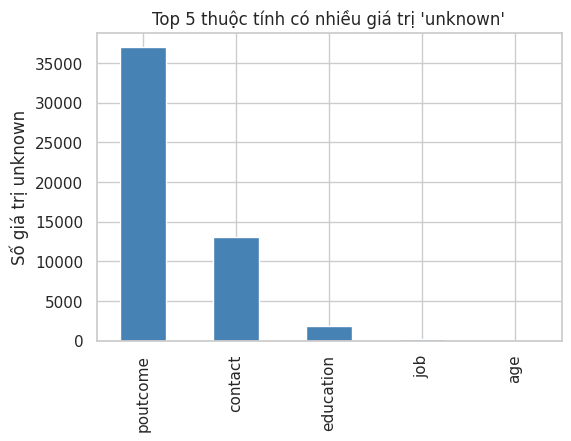

In [5]:
print("Hồng Kim Dung - 6451071009")

top5["so_unknown"].plot(kind="bar", color="steelblue", figsize=(6,4), title="Top 5 thuộc tính có nhiều giá trị 'unknown'")
plt.ylabel("Số giá trị unknown"); plt.show()

**Nhận xét:** bộ dữ liệu không có giá trị rỗng (NaN), nhưng giá trị thiếu được mã hóa bằng "unknown". `poutcome` thiếu nhiều nhất (36.959 dòng, khoảng 81,7%), tiếp theo là `contact` (13.020 dòng, khoảng 28,8%), `education` (1.857 dòng, khoảng 4,1%) và `job` (288 dòng, khoảng 0,6%). Các thuộc tính còn lại không có "unknown".

## Câu 3: Khảo sát thuộc tính quyết định y (đăng ký gửi tiền có kỳ hạn) và các thuộc tính số

Hồng Kim Dung - 6451071009
y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


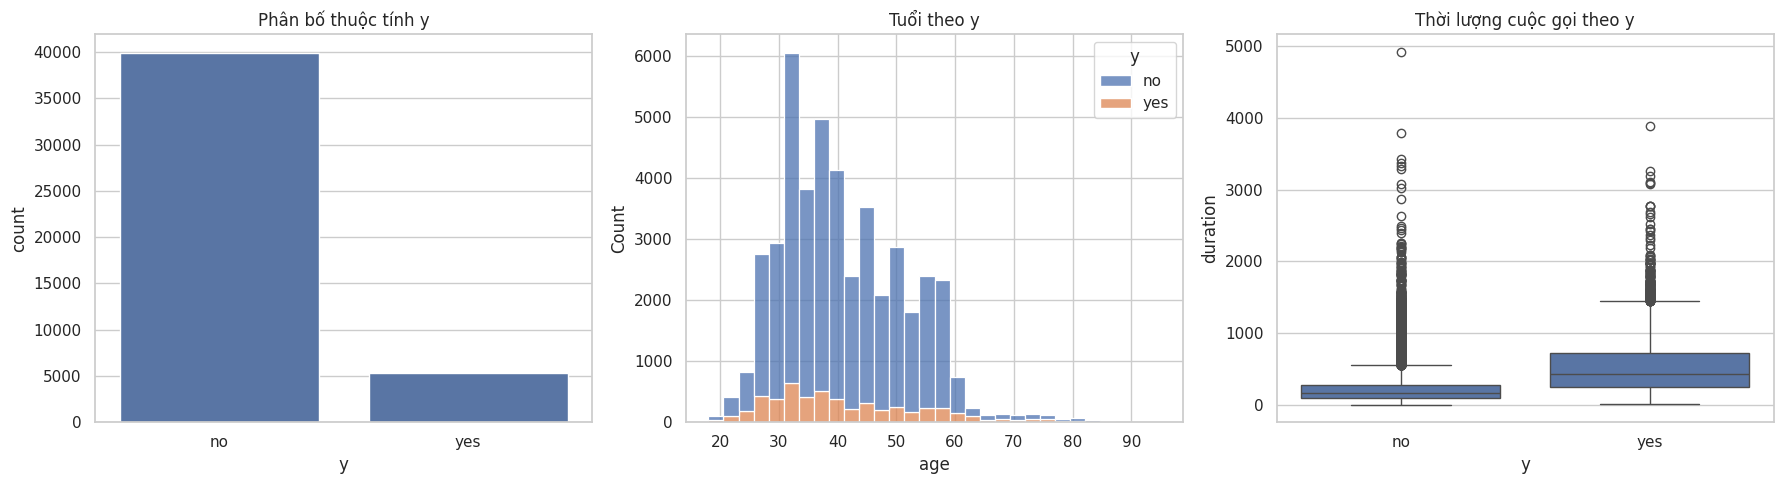

In [6]:
print("Hồng Kim Dung - 6451071009")

print(df["y"].value_counts()); print(df["y"].value_counts(normalize=True).round(3))
fig, ax = plt.subplots(1, 3, figsize=(18,5))
sns.countplot(data=df, x="y", ax=ax[0]); ax[0].set_title("Phân bố thuộc tính y")
sns.histplot(data=df, x="age", hue="y", multiple="stack", bins=30, ax=ax[1]); ax[1].set_title("Tuổi theo y")
sns.boxplot(data=df, x="y", y="duration", ax=ax[2]); ax[2].set_title("Thời lượng cuộc gọi theo y")
plt.tight_layout(); plt.show()

In [7]:
print("Hồng Kim Dung - 6451071009")

df.groupby("y")[["age","balance","duration","campaign","previous"]].median()

Hồng Kim Dung - 6451071009


,age,balance,duration,campaign,previous
y,,,,,
no,39.0,417.0,164.0,2.0,0.0
yes,38.0,733.0,426.0,2.0,0.0


**Nhận xét:** dữ liệu mất cân bằng: chỉ khoảng 11,7% khách hàng đăng ký (yes), 88,3% từ chối (no). Thời lượng cuộc gọi (`duration`) khác biệt rõ nhất: nhóm đăng ký có trung vị khoảng 426 giây, cao hơn nhiều so với nhóm không đăng ký (164 giây). Số dư tài khoản `balance` của nhóm đăng ký cũng cao hơn (trung vị 733 so với 417 euro), còn tuổi gần như không khác biệt (38 và 39).

## Câu 4: Khảo sát các thuộc tính nhân khẩu (job, marital, education) với y

Hồng Kim Dung - 6451071009


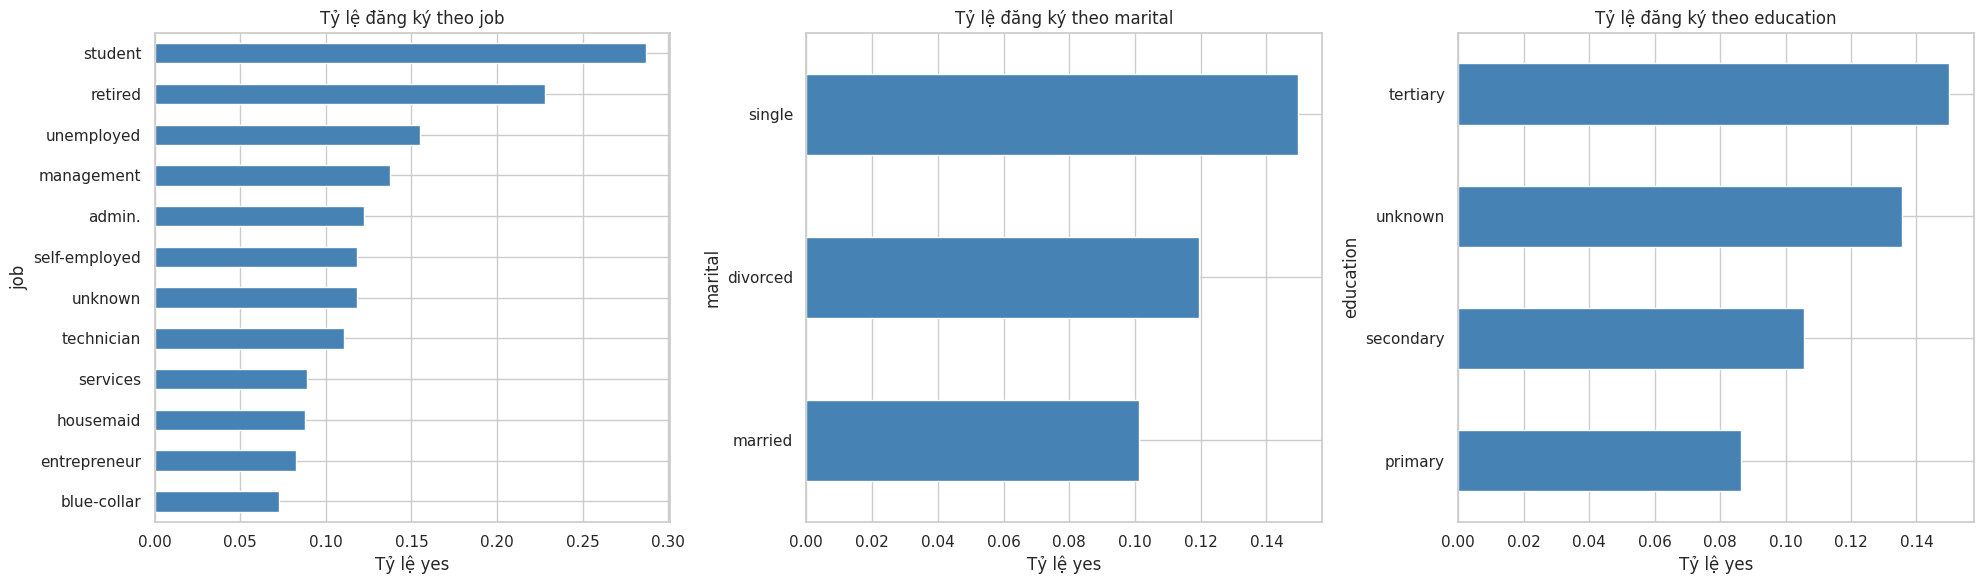

In [8]:
print("Hồng Kim Dung - 6451071009")

fig, ax = plt.subplots(1, 3, figsize=(20,6))
for a, col in zip(ax, ["job","marital","education"]):
    rate = df.assign(yes=(df["y"]=="yes")).groupby(col)["yes"].mean().sort_values()
    rate.plot(kind="barh", ax=a, color="steelblue"); a.set_title(f"Tỷ lệ đăng ký theo {col}"); a.set_xlabel("Tỷ lệ yes")
plt.tight_layout(); plt.show()

In [9]:
print("Hồng Kim Dung - 6451071009")

for col in ["job","marital","education"]:
    print((df.assign(yes=(df["y"]=="yes")).groupby(col)["yes"].mean().round(3)).sort_values(), "\n")

Hồng Kim Dung - 6451071009
job
blue-collar      0.073
entrepreneur     0.083
housemaid        0.088
services         0.089
technician       0.111
self-employed    0.118
unknown          0.118
admin.           0.122
management       0.138
unemployed       0.155
retired          0.228
student          0.287
Name: yes, dtype: float64 

marital
married     0.101
divorced    0.119
single      0.149
Name: yes, dtype: float64 

education
primary      0.086
secondary    0.106
unknown      0.136
tertiary     0.150
Name: yes, dtype: float64 



**Nhận xét:** nhóm sinh viên (student) có tỷ lệ đăng ký cao nhất (khoảng 28,7%), tiếp theo là người về hưu (retired, khoảng 22,8%); nhóm lao động chân tay (blue-collar) thấp nhất (khoảng 7,3%). Người chưa kết hôn (single) đăng ký nhiều hơn (14,9%) so với người đã kết hôn (10,1%). Trình độ học vấn càng cao thì tỷ lệ càng cao: primary 8,6%, secondary 10,6%, tertiary 15,0%.

## Câu 5: Khảo sát thuộc tính liên quan đến chiến dịch (contact, poutcome, housing, loan) với y

Hồng Kim Dung - 6451071009


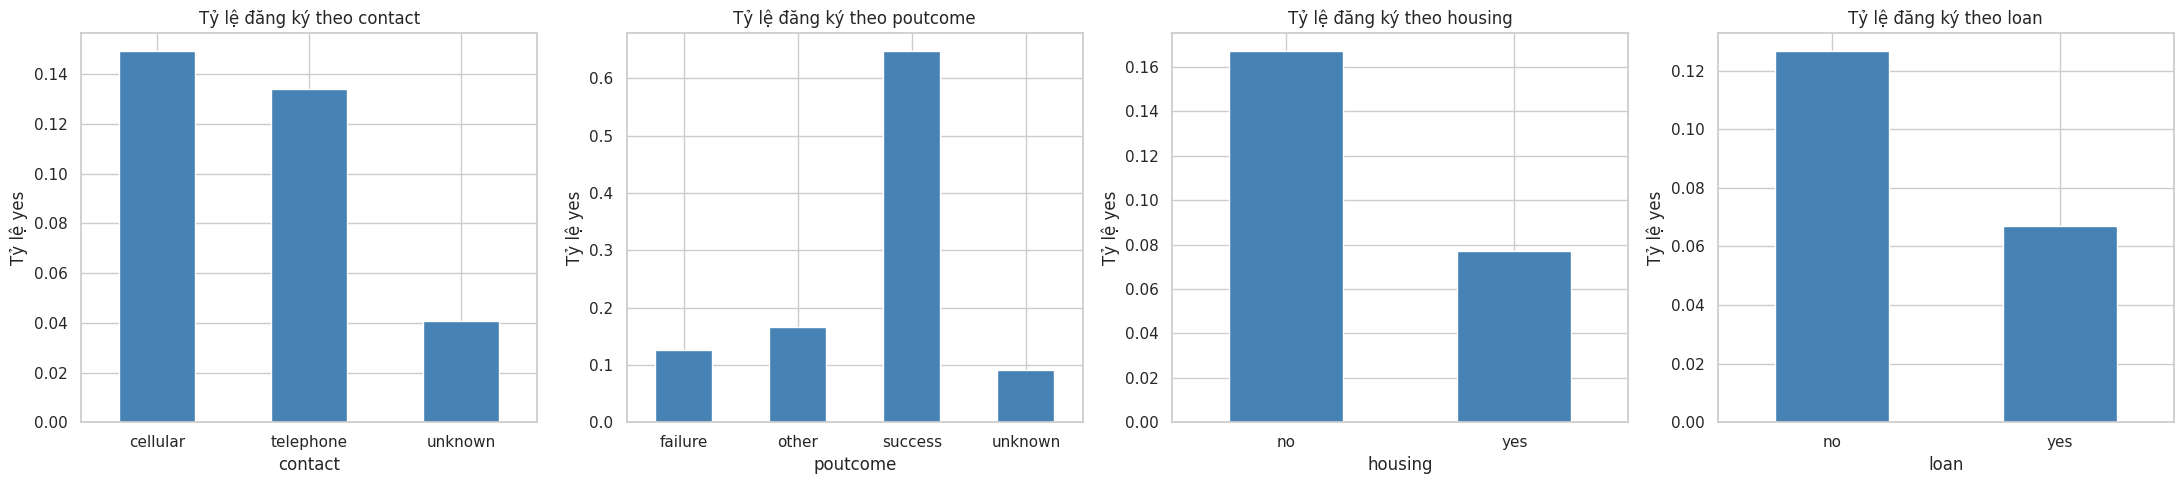

In [10]:
print("Hồng Kim Dung - 6451071009")

fig, ax = plt.subplots(1, 4, figsize=(22,5))
for a, col in zip(ax, ["contact","poutcome","housing","loan"]):
    rate = df.assign(yes=(df["y"]=="yes")).groupby(col)["yes"].mean()
    rate.plot(kind="bar", ax=a, color="steelblue", rot=0); a.set_title(f"Tỷ lệ đăng ký theo {col}"); a.set_ylabel("Tỷ lệ yes")
plt.tight_layout(); plt.show()

In [11]:
print("Hồng Kim Dung - 6451071009")

for col in ["contact","poutcome","housing","loan"]:
    print((df.assign(yes=(df["y"]=="yes")).groupby(col)["yes"].mean().round(3)), "\n")

Hồng Kim Dung - 6451071009
contact
cellular     0.149
telephone    0.134
unknown      0.041
Name: yes, dtype: float64 

poutcome
failure    0.126
other      0.167
success    0.647
unknown    0.092
Name: yes, dtype: float64 

housing
no     0.167
yes    0.077
Name: yes, dtype: float64 

loan
no     0.127
yes    0.067
Name: yes, dtype: float64 



**Nhận xét:** kết quả chiến dịch trước (`poutcome`) ảnh hưởng rất mạnh: khách hàng đã đăng ký ở chiến dịch trước (success) đăng ký lại tới khoảng 64,7%, trong khi nhóm unknown chỉ khoảng 9,2%. Liên lạc qua di động (cellular, 14,9%) hiệu quả hơn điện thoại bàn (telephone, 13,4%); nhóm contact unknown chỉ 4,1%. Khách hàng không vay mua nhà (housing=no, 16,7%) và không vay cá nhân (loan=no, 12,7%) có tỷ lệ đăng ký cao hơn nhóm có vay (7,7% và 6,7%).

## Câu 6: Tiền xử lý dữ liệu

In [12]:
print("Hồng Kim Dung - 6451071009")

# 1. Chuyển "unknown" thành NaN
df_clean = df.replace("unknown", np.nan)
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Hồng Kim Dung - 6451071009
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


In [13]:
print("Hồng Kim Dung - 6451071009")

# 2. poutcome (~82%) và contact (~29%) thiếu quá nhiều -> xóa; pdays = -1 nghĩa là chưa từng liên hệ nên giữ nguyên
df_clean = df_clean.drop(columns=["poutcome","contact"])
# 3. Điền job, education bằng giá trị xuất hiện nhiều nhất
for col in ["job","education"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
# 4. Xóa dòng trùng lặp
print("Số dòng trùng:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print(df_clean.isnull().sum().sum(), "giá trị rỗng còn lại; kích thước:", df_clean.shape)

Hồng Kim Dung - 6451071009
Số dòng trùng: 0
0 giá trị rỗng còn lại; kích thước: (45211, 15)


In [14]:
print("Hồng Kim Dung - 6451071009")

# 5. Mã hóa: thuộc tính nhị phân yes/no -> 1/0, month -> số, các thuộc tính phân loại còn lại -> one-hot
for col in ["default","housing","loan","y"]:
    df_clean[col] = df_clean[col].map({"no":0, "yes":1})
months = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
df_clean["month"] = df_clean["month"].map({m:i+1 for i,m in enumerate(months)})
df_clean = pd.get_dummies(df_clean, columns=["job","marital","education"], drop_first=True, dtype=int)
print(df_clean.shape)
df_clean.head()

Hồng Kim Dung - 6451071009
(45211, 26)


,age,default,balance,housing,loan,day,month,duration,campaign,pdays,...,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_married,marital_single,education_secondary,education_tertiary
0,58,0,2143,1,0,5,5,261,1,-1,...,0,0,0,0,0,0,1,0,0,1
1,44,0,29,1,0,5,5,151,1,-1,...,0,0,0,0,1,0,0,1,1,0
2,33,0,2,1,1,5,5,76,1,-1,...,0,0,0,0,0,0,1,0,1,0
3,47,0,1506,1,0,5,5,92,1,-1,...,0,0,0,0,0,0,1,0,1,0
4,33,0,1,0,0,5,5,198,1,-1,...,0,0,0,0,0,0,0,1,1,0


In [15]:
print("Hồng Kim Dung - 6451071009")
df_clean.info()

Hồng Kim Dung - 6451071009
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   age                  45211 non-null  int64
 1   default              45211 non-null  int64
 2   balance              45211 non-null  int64
 3   housing              45211 non-null  int64
 4   loan                 45211 non-null  int64
 5   day                  45211 non-null  int64
 6   month                45211 non-null  int64
 7   duration             45211 non-null  int64
 8   campaign             45211 non-null  int64
 9   pdays                45211 non-null  int64
 10  previous             45211 non-null  int64
 11  y                    45211 non-null  int64
 12  job_blue-collar      45211 non-null  int64
 13  job_entrepreneur     45211 non-null  int64
 14  job_housemaid        45211 non-null  int64
 15  job_management       45211 non-null  int64


**Nhận xét:** sau tiền xử lý dữ liệu không còn giá trị thiếu, các thuộc tính đều ở dạng số, sẵn sàng cho bước xây dựng mô hình. `poutcome` và `contact` bị xóa vì thiếu quá nhiều; `job`, `education` được điền bằng giá trị phổ biến nhất.